In [1]:
#Purnomo Jeremy Bambang_202431026
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## PRE PROCESSING

In [2]:
#Purnomo Jeremy Bambang_202431026
df = pd.read_csv('wilayah_indonesia.csv', sep=",")
df

,nama,provinsi,kecamatan,kelurahan,desa,jenis
0,Aceh Barat,Aceh,12,0,322,Kabupaten
1,Aceh Barat Daya,Aceh,9,0,152,Kabupaten
2,Aceh Besar,Aceh,23,0,604,Kabupaten
3,Aceh Jaya,Aceh,9,0,172,Kabupaten
4,Aceh Selatan,Aceh,18,0,260,Kabupaten
...,...,...,...,...,...,...
509,Ternate,Maluku Utara,8,78,0,Kota
510,Tidore Kepulauan,Maluku Utara,8,40,49,Kota
511,Tomohon,Sulawesi Utara,5,44,0,Kota
512,Tual,Maluku,5,3,27,Kota


In [3]:
#Purnomo Jeremy Bambang_202431026
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   nama       514 non-null    object
 1   provinsi   514 non-null    object
 2   kecamatan  514 non-null    int64 
 3   kelurahan  514 non-null    int64 
 4   desa       514 non-null    int64 
 5   jenis      514 non-null    object
dtypes: int64(3), object(3)
memory usage: 24.2+ KB


In [4]:
#Purnomo Jeremy Bambang_202431026
df.describe()

,kecamatan,kelurahan,desa
count,514.000000,514.000000,514.000000
mean,14.151751,16.570039,146.429961
std,8.118297,23.215659,122.005065
min,2.000000,0.000000,0.000000
25%,8.000000,3.000000,61.250000
50%,12.000000,9.000000,125.000000
75%,19.000000,21.000000,215.750000
max,51.000000,177.000000,852.000000


In [5]:
#Purnomo Jeremy Bambang_202431026
df.isna().sum()

nama         0
provinsi     0
kecamatan    0
kelurahan    0
desa         0
jenis        0
dtype: int64

In [6]:
#Purnomo Jeremy Bambang_202431026
df['jenis'].unique()

array(['Kabupaten', 'Kota'], dtype=object)

## Modelling

In [7]:
#Purnomo Jeremy Bambang_202431026
x = df.drop(['nama', 'provinsi', 'jenis'], axis=1)
y = df['jenis']

In [8]:
#Purnomo Jeremy Bambang_202431026
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

for i, label in enumerate(le.classes_):
    print(f"{i} = {label}")

x = np.array(x, dtype='float64')
y = np.array(y, dtype='int64')

0 = Kabupaten
1 = Kota


In [9]:
#Purnomo Jeremy Bambang_202431026
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state=0)

In [10]:
#Purnomo Jeremy Bambang_202431026
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier()
classifier.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


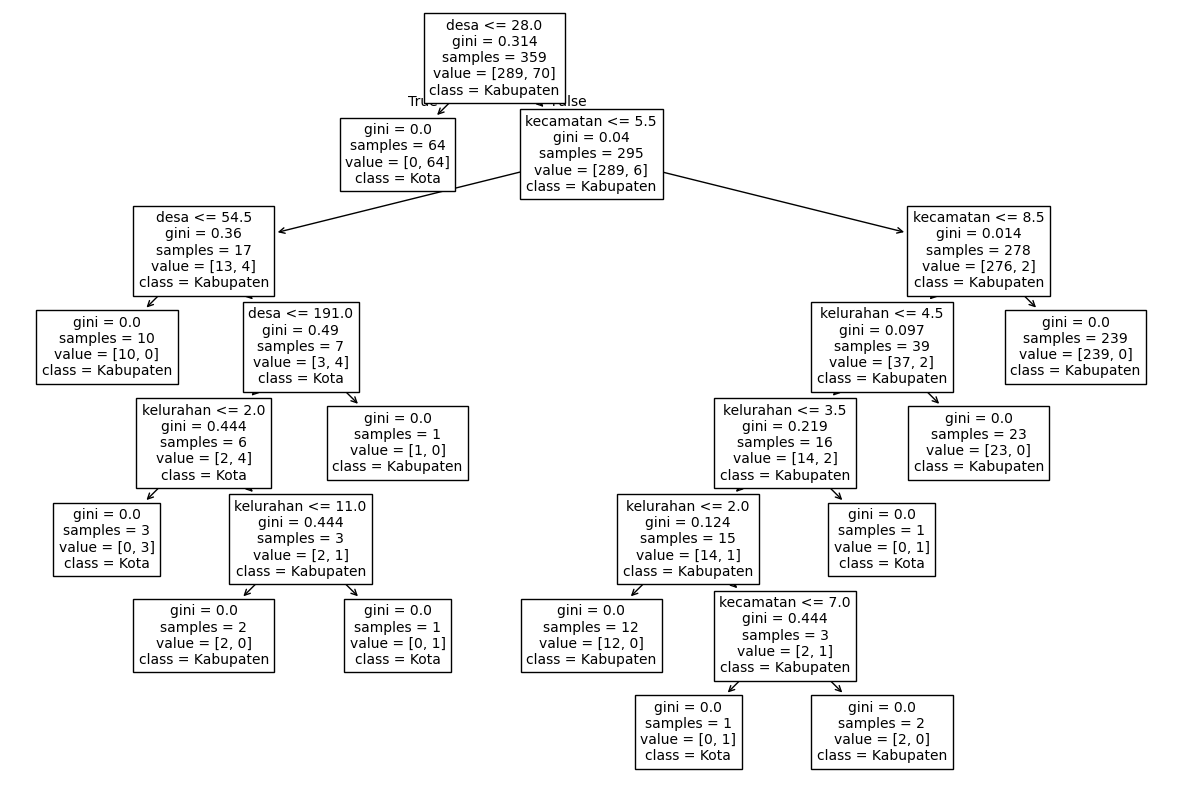

In [11]:
#Purnomo Jeremy Bambang_202431026
from sklearn import tree

plt.subplots(figsize = (15,10))
tree.plot_tree(classifier, feature_names=['kecamatan', 'kelurahan', 'desa'], class_names=le.classes_, fontsize = 10)
plt.show()

In [12]:
#Purnomo Jeremy Bambang_202431026
#data baru: [kecamatan, kelurahan, desa]
y_baru = classifier.predict([[6, 30, 0]])
print(y_baru)
print("Hasil prediksi:", le.inverse_transform(y_baru))

[1]
Hasil prediksi: ['Kota']


In [13]:
#Purnomo Jeremy Bambang_202431026
from sklearn.metrics import accuracy_score

y_pred = classifier.predict(x_test)
akurasi = accuracy_score(y_test, y_pred)
print(akurasi)

0.9419354838709677


In [14]:
#Purnomo Jeremy Bambang_202431026
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

   Kabupaten       0.97      0.96      0.96       127
        Kota       0.83      0.86      0.84        28

    accuracy                           0.94       155
   macro avg       0.90      0.91      0.90       155
weighted avg       0.94      0.94      0.94       155

